# Imbalance-Aware Skin Lesion Classification on HAM10000
## EfficientNetB0 Transfer Learning with Grad-CAM Explainability

This notebook trains and evaluates a seven-class skin-lesion image classifier using the HAM10000 dermoscopic image dataset.

**Workflow**
1. Load metadata and locate the two image folders.
2. Explore the seven-class distribution.
3. Create stratified train, validation, and test subsets.
4. Apply image augmentation and class-weighted learning.
5. Fine-tune an ImageNet-pretrained EfficientNetB0 model.
6. Evaluate with class-wise metrics, a confusion matrix, and one-vs-rest ROC-AUC.
7. Generate a Grad-CAM visualization for an example prediction.

> **Research-use disclaimer:** This notebook is an educational research experiment, not a medical device. It must not be used to diagnose, screen, or make treatment decisions.

The raw HAM10000 dataset is not included in this repository. Download it from [Harvard Dataverse](https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/DBW86T) or the [Kaggle mirror](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000). Review the license and terms on the source you use. For local execution, set the `HAM10000_DATASET_DIR` environment variable to the directory containing `HAM10000_metadata.csv` and both image folders.


In [1]:
# Import Required Libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## Dataset Description

HAM10000 contains 10,015 dermatoscopic images across seven diagnostic categories:

| Code | Category |
|---|---|
| AKIEC | Actinic keratoses / intraepithelial carcinoma |
| BCC | Basal cell carcinoma |
| BKL | Benign keratosis-like lesions |
| DF | Dermatofibroma |
| MEL | Melanoma |
| NV | Melanocytic nevi |
| VASC | Vascular lesions |

The dataset is strongly imbalanced: NV is the majority class, while DF and VASC have comparatively few images.

**Important evaluation note:** The supplied experiment uses an image-level stratified split. HAM10000 can contain multiple images of the same lesion, so a lesion-level grouped split should be used in future validation to reduce potential identity leakage.


In [2]:
# Load HAM10000 Metadata

from pathlib import Path
import os
import pandas as pd

# Preferred locations:
# 1. HAM10000_DATASET_DIR environment variable
# 2. Kaggle's common HAM10000 dataset location
# 3. A local ./data directory
configured_root = os.environ.get("HAM10000_DATASET_DIR")

candidate_roots = []
if configured_root:
    candidate_roots.append(Path(configured_root))

candidate_roots.extend([
    Path("/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"),
    Path("data"),
])

metadata_path = None
for candidate in candidate_roots:
    candidate_metadata = candidate / "HAM10000_metadata.csv"
    if candidate_metadata.exists():
        metadata_path = candidate_metadata
        DATASET_ROOT = candidate
        break

# If the common paths do not match, search Kaggle input directories.
if metadata_path is None and Path("/kaggle/input").exists():
    matches = list(Path("/kaggle/input").rglob("HAM10000_metadata.csv"))
    if matches:
        metadata_path = matches[0]
        DATASET_ROOT = metadata_path.parent

if metadata_path is None:
    raise FileNotFoundError(
        "HAM10000_metadata.csv was not found. Download the HAM10000 dataset "
        "and either place it under ./data or set HAM10000_DATASET_DIR to the "
        "directory containing HAM10000_metadata.csv."
    )

df = pd.read_csv(metadata_path)
print("Dataset root:", DATASET_ROOT.resolve())
print("Metadata file:", metadata_path.resolve())
df.head()


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [3]:
# Check class distribution

class_counts = df['dx'].value_counts()

print(class_counts)

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


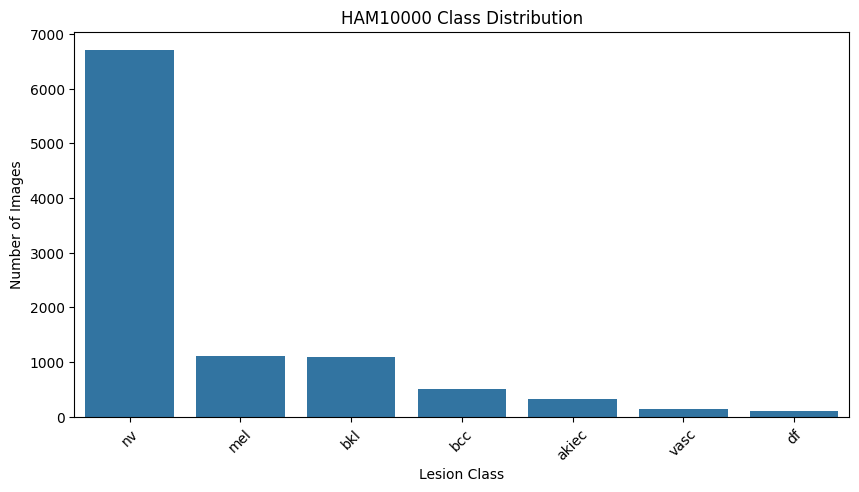

In [4]:
# Visualize Class Distribution

plt.figure(figsize=(10,5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("HAM10000 Class Distribution")
plt.xlabel("Lesion Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.show()

In [5]:
# Inspect the dataset directory

print("Dataset root:", DATASET_ROOT)
for dirname, folders, filenames in os.walk(DATASET_ROOT):
    print("Folder:", dirname)
    print("Number of files:", len(filenames))
    print("Sample files:", filenames[:5])
    print("----------------------")


Folder: /kaggle/input
Number of files: 0
Sample files: []
----------------------
Folder: /kaggle/input/datasets
Number of files: 0
Sample files: []
----------------------
Folder: /kaggle/input/datasets/kmader
Number of files: 0
Sample files: []
----------------------
Folder: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
Number of files: 5
Sample files: ['hmnist_8_8_RGB.csv', 'hmnist_28_28_RGB.csv', 'hmnist_8_8_L.csv', 'hmnist_28_28_L.csv', 'HAM10000_metadata.csv']
----------------------
Folder: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1
Number of files: 5000
Sample files: ['ISIC_0028933.jpg', 'ISIC_0028394.jpg', 'ISIC_0027799.jpg', 'ISIC_0028100.jpg', 'ISIC_0027960.jpg']
----------------------
Folder: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_1
Number of files: 5000
Sample files: ['ISIC_0028933.jpg', 'ISIC_0028394.jpg', 'ISIC_0027799.jpg', 'ISIC_0028100.jpg', 'ISIC_0027960.jpg']
----------------------
F

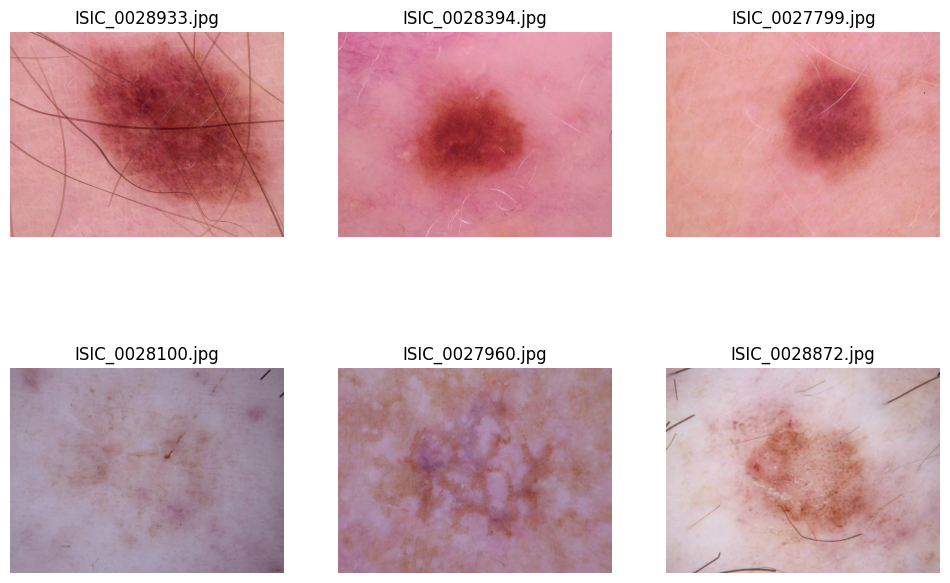

In [6]:
# Display sample dermoscopic images

import matplotlib.pyplot as plt
from PIL import Image

def resolve_image_folder(folder_name):
    candidates = [
        DATASET_ROOT / folder_name,
        DATASET_ROOT / folder_name.lower()
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    matches = list(DATASET_ROOT.rglob(folder_name))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Could not find {folder_name} under {DATASET_ROOT}")

image_folder = resolve_image_folder("HAM10000_images_part_1")
image_files = sorted([p for p in image_folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg"}])[:6]

plt.figure(figsize=(12, 8))
for i, image_path in enumerate(image_files):
    img = Image.open(image_path)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(image_path.name)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [7]:
# Load metadata and prepare image filenames

df = pd.read_csv(metadata_path)
df["image_name"] = df["image_id"] + ".jpg"
df.head()


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_name
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,ISIC_0027419.jpg
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,ISIC_0025030.jpg
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,ISIC_0026769.jpg
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,ISIC_0025661.jpg
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,ISIC_0031633.jpg


In [8]:
# Locate images in both HAM10000 image folders

folder1 = resolve_image_folder("HAM10000_images_part_1")
folder2 = resolve_image_folder("HAM10000_images_part_2")

def find_image_path(image_name):
    path1 = folder1 / image_name
    path2 = folder2 / image_name

    if path1.exists():
        return str(path1)
    if path2.exists():
        return str(path2)
    return None

df["image_path"] = df["image_name"].apply(find_image_path)
df.head()


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_name,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,ISIC_0027419.jpg,/kaggle/input/datasets/kmader/skin-cancer-mnis...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,ISIC_0025030.jpg,/kaggle/input/datasets/kmader/skin-cancer-mnis...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,ISIC_0026769.jpg,/kaggle/input/datasets/kmader/skin-cancer-mnis...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,ISIC_0025661.jpg,/kaggle/input/datasets/kmader/skin-cancer-mnis...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,ISIC_0031633.jpg,/kaggle/input/datasets/kmader/skin-cancer-mnis...


In [9]:
# Check missing image paths

missing = df['image_path'].isnull().sum()

print("Missing images:", missing)

Missing images: 0


In [10]:
# Encode lesion classes into numerical labels

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df['label'] = label_encoder.fit_transform(df['dx'])

# Show mapping
class_mapping = dict(zip(label_encoder.classes_, 
                         label_encoder.transform(label_encoder.classes_)))

print(class_mapping)

# Check dataframe
df[['dx','label']].head()

{'akiec': np.int64(0), 'bcc': np.int64(1), 'bkl': np.int64(2), 'df': np.int64(3), 'mel': np.int64(4), 'nv': np.int64(5), 'vasc': np.int64(6)}


,dx,label
0,bkl,2
1,bkl,2
2,bkl,2
3,bkl,2
4,bkl,2


In [26]:
# Stratified image-level train / validation / test split (70 / 15 / 15)

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

# Audit whether lesion identifiers appear in more than one split.
# Any overlap indicates that the image-level split is not lesion-independent.
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

print("Train/validation lesion overlap:", len(train_lesions & val_lesions))
print("Train/test lesion overlap:", len(train_lesions & test_lesions))
print("Validation/test lesion overlap:", len(val_lesions & test_lesions))


Training samples: 7010
Validation samples: 1502
Testing samples: 1503


In [28]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 32


# Training augmentation
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8,1.2]
)


# Validation/Test
# EfficientNet already has preprocessing internally
val_test_datagen = ImageDataGenerator()


print("Data generators created successfully")

Data generators created successfully


In [29]:
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='dx',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    shuffle=True
)


val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='dx',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    shuffle=False
)


test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='image_path',
    y_col='dx',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    shuffle=False
)


print("Generators ready")

Found 7010 validated image filenames belonging to 7 classes.
Found 1502 validated image filenames belonging to 7 classes.
Found 1503 validated image filenames belonging to 7 classes.
Generators ready


In [30]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np


class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label']),
    y=train_df['label']
)


class_weights = dict(
    enumerate(class_weights_array)
)


print(class_weights)

{0: np.float64(4.37305053025577), 1: np.float64(2.7817460317460316), 2: np.float64(1.3022478172023035), 3: np.float64(12.36331569664903), 4: np.float64(1.285530900421786), 5: np.float64(0.21338772031292808), 6: np.float64(10.115440115440116)}


In [31]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam


IMG_SIZE = 224
NUM_CLASSES = 7


# Load pretrained EfficientNetB0
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)


# Fine tuning setup
base_model.trainable = True


# Freeze all backbone layers except the final 50
for layer in base_model.layers[:-50]:
    layer.trainable = False


# Add classifier
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)

x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

output = Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)


model = Model(
    inputs=base_model.input,
    outputs=output
)


model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_10        │ (None, 224, 224,  │          0 │ input_layer_5[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_5     │ (None, 224, 224,  │          7 │ rescaling_10[0][… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_11        │ (None, 224, 224,  │          0 │ normalization_5[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_11[0][… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,214,442 (16.08 MB)

 Trainable params: 2,691,735 (10.27 MB)

 Non-trainable params: 1,522,707 (5.81 MB)

In [32]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from pathlib import Path

# Keep generated model files outside the Git repository.
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = OUTPUT_DIR / "best_model.keras"

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-7
)

checkpoint = ModelCheckpoint(
    str(checkpoint_path),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

print("Model compiled successfully")
print("Checkpoint path:", checkpoint_path)


Model compiled successfully


In [22]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30,
    class_weight=class_weights,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/30


2026-08-24 20:58:48.563269: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 20:58:48.706096: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 20:58:49.053052: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 20:58:49.194108: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 20:58:49.996057: E external/local_xla/xla/stream_

 15/220 ━━━━━━━━━━━━━━━━━━━━ 2:27 718ms/step - accuracy: 0.1056 - loss: 2.4985

2026-08-24 20:59:19.881468: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 20:59:20.014508: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 20:59:20.324494: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 20:59:20.464504: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 20:59:21.258945: E external/local_xla/xla/stream_

220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - accuracy: 0.1233 - loss: 2.1554

2026-08-24 21:02:30.030302: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 21:02:30.173144: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 21:02:30.517390: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 21:02:30.658273: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-24 21:02:31.423792: E external/local_xla/xla/stream_

220/220 ━━━━━━━━━━━━━━━━━━━━ 253s 978ms/step - accuracy: 0.1314 - loss: 2.0545 - val_accuracy: 0.1704 - val_loss: 1.9562 - learning_rate: 1.0000e-05
Epoch 2/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 130s 589ms/step - accuracy: 0.1606 - loss: 1.9703 - val_accuracy: 0.2117 - val_loss: 1.8627 - learning_rate: 1.0000e-05
Epoch 3/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 128s 581ms/step - accuracy: 0.1839 - loss: 1.8877 - val_accuracy: 0.2577 - val_loss: 1.8065 - learning_rate: 1.0000e-05
Epoch 4/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 129s 586ms/step - accuracy: 0.2034 - loss: 1.8458 - val_accuracy: 0.2983 - val_loss: 1.7506 - learning_rate: 1.0000e-05
Epoch 5/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 127s 575ms/step - accuracy: 0.2392 - loss: 1.7900 - val_accuracy: 0.3309 - val_loss: 1.6980 - learning_rate: 1.0000e-05
Epoch 6/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 128s 581ms/step - accuracy: 0.2666 - loss: 1.7109 - val_accuracy: 0.3668 - val_loss: 1.6405 - learning_rate: 1.0000e-05
Epoch 7/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 126s 570ms/

In [23]:
# Inspect generated output files

print("Output directory:", OUTPUT_DIR.resolve())
print(os.listdir(OUTPUT_DIR))


['.virtual_documents', 'best_model.keras']


In [24]:
from tensorflow.keras.models import load_model

best_model = load_model(checkpoint_path)
print("Best model loaded from:", checkpoint_path)


Best model loaded


In [26]:
test_loss, test_accuracy = best_model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

47/47 ━━━━━━━━━━━━━━━━━━━━ 10s 208ms/step - accuracy: 0.6281 - loss: 0.9673
Test Loss: 0.9672636985778809
Test Accuracy: 0.6280771493911743


In [27]:
import numpy as np

# Generate predictions
predictions = best_model.predict(test_generator)

# Convert probabilities to class labels
y_pred = np.argmax(predictions, axis=1)

# Get true labels
y_true = test_generator.classes

print("Prediction completed")
print("Number of predictions:", len(y_pred))

47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 349ms/step
Prediction completed
Number of predictions: 1503


In [28]:
from sklearn.metrics import classification_report

class_names = list(test_generator.class_indices.keys())

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

       akiec       0.55      0.24      0.34        49
         bcc       0.48      0.58      0.53        77
         bkl       0.47      0.52      0.49       165
          df       0.19      0.59      0.29        17
         mel       0.27      0.67      0.39       167
          nv       0.96      0.65      0.78      1006
        vasc       0.39      1.00      0.56        22

    accuracy                           0.63      1503
   macro avg       0.47      0.61      0.48      1503
weighted avg       0.77      0.63      0.67      1503



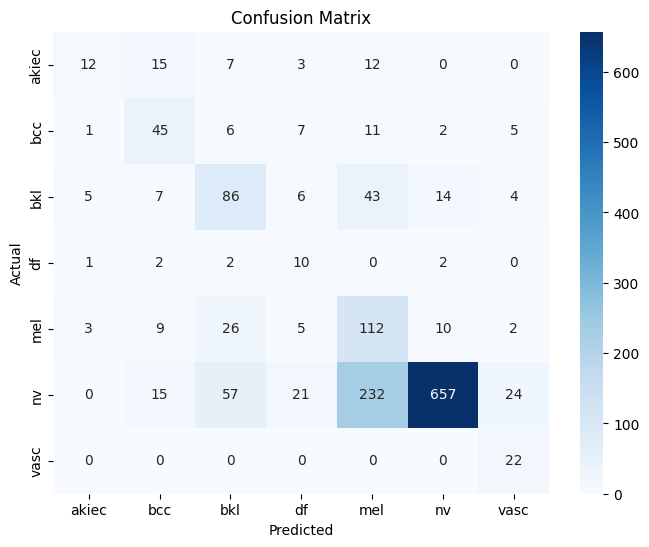

In [29]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

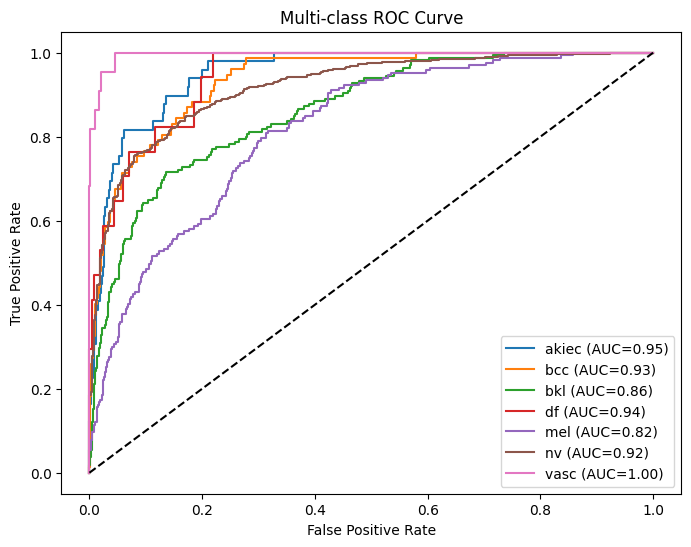

In [30]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# True labels one-hot
y_true_bin = label_binarize(
    y_true,
    classes=list(range(len(class_names)))
)

# Prediction probabilities already available
y_score = predictions

plt.figure(figsize=(8,6))

for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_score[:, i]
    )
    
    roc_auc = auc(fpr, tpr)
    
    plt.plot(
        fpr,
        tpr,
        label=f"{class_names[i]} (AUC={roc_auc:.2f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-class ROC Curve")
plt.legend()
plt.show()

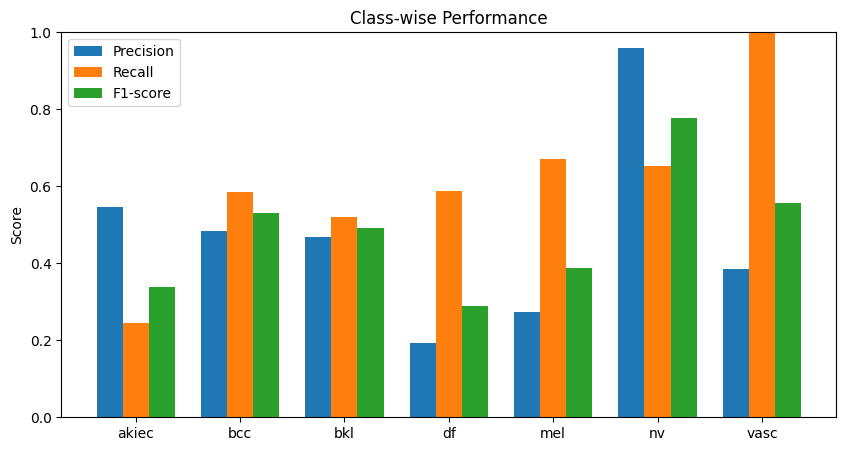

In [31]:
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt
import numpy as np

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average=None
)

x = np.arange(len(class_names))

plt.figure(figsize=(10,5))

plt.bar(x-0.25, precision, width=0.25, label="Precision")
plt.bar(x, recall, width=0.25, label="Recall")
plt.bar(x+0.25, f1, width=0.25, label="F1-score")

plt.xticks(x, class_names)
plt.ylabel("Score")
plt.title("Class-wise Performance")
plt.legend()
plt.ylim(0,1)

plt.show()

In [33]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

print("Grad-CAM libraries ready")

Grad-CAM libraries ready


In [34]:
# Show model layers to find last convolution layer

for i, layer in enumerate(best_model.layers):
    print(i, layer.name, layer.output.shape)

0 input_layer_1 (None, 224, 224, 3)
1 rescaling_2 (None, 224, 224, 3)
2 normalization_1 (None, 224, 224, 3)
3 rescaling_3 (None, 224, 224, 3)
4 stem_conv_pad (None, 225, 225, 3)
5 stem_conv (None, 112, 112, 32)
6 stem_bn (None, 112, 112, 32)
7 stem_activation (None, 112, 112, 32)
8 block1a_dwconv (None, 112, 112, 32)
9 block1a_bn (None, 112, 112, 32)
10 block1a_activation (None, 112, 112, 32)
11 block1a_se_squeeze (None, 32)
12 block1a_se_reshape (None, 1, 1, 32)
13 block1a_se_reduce (None, 1, 1, 8)
14 block1a_se_expand (None, 1, 1, 32)
15 block1a_se_excite (None, 112, 112, 32)
16 block1a_project_conv (None, 112, 112, 16)
17 block1a_project_bn (None, 112, 112, 16)
18 block2a_expand_conv (None, 112, 112, 96)
19 block2a_expand_bn (None, 112, 112, 96)
20 block2a_expand_activation (None, 112, 112, 96)
21 block2a_dwconv_pad (None, 113, 113, 96)
22 block2a_dwconv (None, 56, 56, 96)
23 block2a_bn (None, 56, 56, 96)
24 block2a_activation (None, 56, 56, 96)
25 block2a_se_squeeze (None, 96)
26 b

In [ ]:
# Select one test image and read its sparse integer label correctly

img_batch, label_batch = next(test_generator)

img = img_batch[0]
true_label = int(label_batch[0])  # class_mode='sparse' returns an integer label

img_input = np.expand_dims(img, axis=0)
display_img = img / 255.0

print("Image shape:", img.shape)
print("True class index:", true_label)

plt.figure(figsize=(4, 4))
plt.imshow(display_img)
plt.axis("off")
plt.title("Test Image")
plt.show()


In [ ]:
# Model prediction for selected image

img_input = np.expand_dims(img, axis=0)

prediction = best_model.predict(img_input)

predicted_class = np.argmax(prediction)

confidence = np.max(prediction) * 100

print("Predicted class index:", predicted_class)
print("Confidence:", confidence, "%")

In [ ]:
# Get class names

class_names = list(test_generator.class_indices.keys())

print("Class names:")
print(class_names)

print("True class:", class_names[true_label])
print("Predicted class:", class_names[predicted_class])

In [ ]:
# Calculate final metrics from the same predictions used in the classification report

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("Final Model Performance")
print("-----------------------")
print("Accuracy       :", accuracy)
print("Weighted Precision:", precision)
print("Weighted Recall   :", recall)
print("Weighted F1 Score :", f1)
print("Macro F1 Score    :", macro_f1)


In [80]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("Grad-CAM libraries imported")

Grad-CAM libraries imported


In [81]:
# Define Grad-CAM layer

last_conv_layer_name = "top_conv"

last_conv_layer = best_model.get_layer(last_conv_layer_name)

print("Last convolution layer:", last_conv_layer.name)

Last convolution layer: top_conv


In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    grads = tape.gradient(class_score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)

    # Avoid division by zero for a degenerate heatmap.
    heatmap_max = tf.reduce_max(heatmap)
    heatmap = tf.math.divide_no_nan(heatmap, heatmap_max)

    return heatmap.numpy()


print("Grad-CAM function created")


In [ ]:
# Generate Grad-CAM heatmap for the selected single test image

heatmap = make_gradcam_heatmap(
    img_input,
    best_model,
    last_conv_layer_name
)

plt.figure(figsize=(6, 6))
plt.imshow(heatmap, cmap="jet")
plt.colorbar()
plt.title("Grad-CAM Heatmap")
plt.axis("off")
plt.show()


In [ ]:
import cv2

# Resize heatmap to original image size
heatmap_resized = cv2.resize(
    heatmap,
    (img.shape[1], img.shape[0])
)

# Convert heatmap to 0-255
heatmap_resized = np.uint8(255 * heatmap_resized)

# Apply color map
heatmap_color = cv2.applyColorMap(
    heatmap_resized,
    cv2.COLORMAP_JET
)

# Convert original image to uint8
original_img = np.uint8(255 * img)

# Overlay heatmap on image
overlay = cv2.addWeighted(
    original_img,
    0.6,
    heatmap_color,
    0.4,
    0
)

plt.figure(figsize=(6,6))
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")
plt.show()

In [ ]:
plt.figure(figsize=(12,4))

# Original image
plt.subplot(1,3,1)
plt.imshow(original_img)
plt.title("Original Image")
plt.axis("off")


# Heatmap
plt.subplot(1,3,2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")


# Overlay
plt.subplot(1,3,3)
plt.imshow(overlay)
plt.title(
    f"Prediction: {class_names[predicted_class]}\nConfidence: {confidence:.2f}%"
)
plt.axis("off")

plt.show()

## Conclusion

This experiment evaluates an EfficientNetB0-based approach to seven-class HAM10000 skin-lesion image classification, with class-weighted training and Grad-CAM visualization.

The saved test results show 62.81% accuracy, a weighted F1-score of 0.67, and a macro F1-score of 0.48. The gap between weighted and macro F1 highlights weaker performance on some minority classes and the continuing impact of class imbalance.

Grad-CAM provides a qualitative visualization of regions associated with a selected prediction; it does not establish medical validity or explainability in a clinical sense.

Future work should prioritize lesion-level grouped splitting to reduce potential identity leakage, validation on independent datasets, and improved evaluation and learning strategies for underrepresented classes. This experiment is for educational research only and is not intended for clinical use.
